# JEPA

A predictor receives a partially observed digit and predicts the clean view in an embedding space. This small paired-view JEPA uses a moving-average target and a variance penalty to discourage collapse.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Representation Learning folder.")

## Context and target

The two encoders start with the same weights. Only the online encoder and predictor receive gradients.

In [2]:
import copy
import matplotlib.pyplot as plt
import torch
from torch import nn
from gallery.vision import digits_split
from gallery.neural import seed_cpu
from gallery.representations import probe_encoders, update_teacher


def make_encoder():
    return nn.Sequential(nn.Linear(64, 96), nn.GELU(), nn.Linear(96, 32))

## Predict a clean embedding

Each coordinate is hidden independently with probability 0.32. The variance penalty follows VICReg. Digit labels stratify the initial partition and train the downstream classifier. The embedding objective uses only the images.

In [3]:
seed_cpu()
train, test, y, y_test = digits_split()
X = torch.tensor(train).flatten(1)
T = torch.tensor(test).flatten(1)

encoder = make_encoder()
initial = copy.deepcopy(encoder)
teacher = copy.deepcopy(encoder).eval().requires_grad_(False)
predictor = nn.Sequential(nn.Linear(32, 64), nn.GELU(), nn.Linear(64, 32))
opt = torch.optim.AdamW([*encoder.parameters(), *predictor.parameters()], lr=0.0015)
history = []
for epoch in range(24):
    total = 0.0
    for ids in torch.randperm(len(X)).split(64):
        clean = X[ids]
        context = clean * (torch.rand_like(clean) > 0.32)
        z = encoder(context)
        with torch.no_grad():
            target = nn.functional.layer_norm(teacher(clean), (32,))
        fit = nn.functional.smooth_l1_loss(predictor(z), target)
        variance = torch.relu(0.75 - (z.var(0, unbiased=False) + 1e-4).sqrt()).mean()
        loss = fit + 0.65 * variance
        opt.zero_grad()
        loss.backward()
        opt.step()
        update_teacher(teacher, encoder)
        total += loss.item() * len(ids)
    history.append(total / len(X))
with torch.no_grad():
    torch.manual_seed(103)
    hidden = T * (torch.rand_like(T) > 0.32)
    discrepancy = (
        (predictor(encoder(hidden)) - nn.functional.layer_norm(teacher(T), (32,))).abs().mean()
    )
print(f"Held-out latent MAE: {discrepancy.item():.4f}")

Held-out latent MAE: 0.1697


## Frozen linear probes

Identical probe settings compare raw pixels, the initial encoder and the learned encoder. PCA is fitted on training features.

Raw input: accuracy 0.969 | balanced accuracy 0.969 | macro F1 0.969
Random encoder: accuracy 0.956 | balanced accuracy 0.955 | macro F1 0.955
Trained encoder: accuracy 0.791 | balanced accuracy 0.790 | macro F1 0.787
Held-out mean feature SD: 2.1801 | Effective covariance rank: 2.09


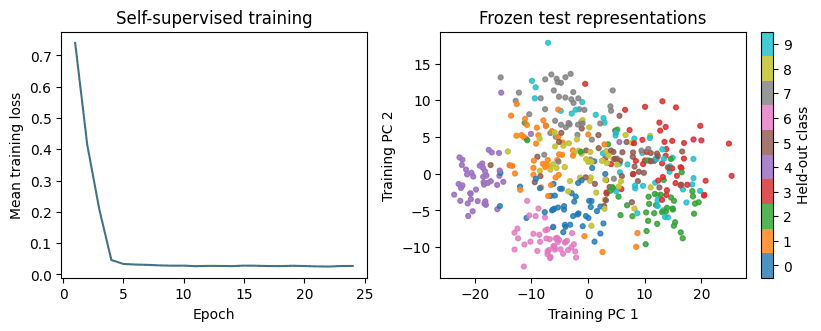

In [4]:
probe_encoders(initial, encoder, X, T, y, y_test, history)
plt.show()

## Reading the result

A small prediction loss alone can be achieved by collapsing the representation. Feature spread, effective rank and the random-encoder probe give the loss a scale.

## References

[LeCun, A Path Towards Autonomous Machine Intelligence (2022)](https://openreview.net/pdf?id=BZ5a1r-kVsf)

[Bardes, Ponce and LeCun, VICReg (2022)](https://arxiv.org/abs/2105.04906)

[Alpaydin and Kaynak, Optical Recognition of Handwritten Digits, UCI, CC BY 4.0](https://doi.org/10.24432/C50P49)

[Frozen probes and masked-prediction training](../gallery/representations.py)